In [1]:
import math
import random
NAMA = ("Depo", "A", "B", "C", "D",
"E", "F", "G", "H")
POSISI = (
(0, 0), (2, 5), (5, 8), (9, 7), (11, 3),
(8, 0), (5, 2), (2, -2), (-1, 3),
)
def jarak_antar(i, j):
    x1, y1 = POSISI[i]
    x2, y2 = POSISI[j]
    return math.hypot(x2 - x1, y2 - y1)

def buat_individu(rng):
    rute = list(range(1, len(NAMA)))
    #TODO: acak rute menggunakan rng
    rng.shuffle(rute)
    return rute

In [2]:
def jarak_total(rute):
    # TODO: jumlahkan jarak Depo -> titik pertama,
    # antar titik berurutan, lalu titik terakhir -> Depo
    total = jarak_antar(0, rute[0])
    for asal, tujuan in zip(rute, rute[1:]):
        total += jarak_antar(asal, tujuan)
    total += jarak_antar(rute[-1], 0)
    return total
def fitness(rute):
    # TODO: kembalikan 1 / (1 + jarak_total(rute))
    return 1 / (1 + jarak_total(rute))

In [3]:
def turnamen(populasi, rng, ukuran=3):
    peserta = rng.sample(populasi, ukuran)
    # TODO: pilih peserta dengan fitness terbesar
    # dan kembalikan salinan list-nya
    return list(max(peserta, key=fitness))

In [4]:
def crossover_urutan(induk1, induk2, rng):
    n = len(induk1)
    awal, akhir = sorted(rng.sample(range(n), 2))
    akhir += 1 # batas akhir slice tidak ikut disalin
    anak = [None] * n
    # TODO: salin segmen induk1[awal:akhir] ke anak
    anak[awal:akhir] = induk1[awal:akhir]
    # TODO: buat daftar titik dari induk2 yang belum ada di anak
    sisa = [g for g in induk2 if g not in anak]
    it = iter(sisa)
    # TODO: isi posisi None dari kiri ke kanan memakai daftar itu
    for i in range(n):
        if anak[i] is None:
            anak[i] = next(it)
    return anak

In [5]:
def mutasi_tukar(rute, rng, peluang):
    hasil = rute[:]
    # TODO: jika rng.random() < peluang, pilih dua indeks
    # berbeda dan tukar kedua titik pada hasil
    if rng.random() < peluang:
        i, j = rng.sample(range(len(hasil)), 2)
        hasil[i], hasil[j] = hasil[j], hasil[i]
    return hasil

In [6]:
def jalankan_ga(seed=5054251011, ukuran_populasi=60, generasi=150,
    peluang_crossover=0.85, peluang_mutasi=0.2,
    elit=2):
    rng = random.Random(seed)
    populasi = [buat_individu(rng)
    for _ in range(ukuran_populasi)]
    terbaik = min(populasi, key=jarak_total)[:]
    riwayat = [jarak_total(terbaik)]
    for _ in range(generasi):
        baru = []
        # TODO: salin elit individu dengan jarak terpendek
        # dari populasi ke baru
        for individu in sorted(populasi, key=jarak_total)[:elit]:
            baru.append(individu[:])
        while len(baru) < ukuran_populasi:
            induk1 = turnamen(populasi, rng)
            induk2 = turnamen(populasi, rng)
            # TODO: lakukan crossover dengan peluang yang
            # ditentukan; jika gagal, salin kedua induk
            if rng.random() < peluang_crossover:
                anak1 = crossover_urutan(induk1, induk2, rng)
                anak2 = crossover_urutan(induk2, induk1, rng)
            else:
                anak1, anak2 = induk1[:], induk2[:]
            # TODO: mutasikan kedua anak
            anak1 = mutasi_tukar(anak1, rng, peluang_mutasi)
            anak2 = mutasi_tukar(anak2, rng, peluang_mutasi)
            for anak in (anak1, anak2):
                if len(baru) < ukuran_populasi:
                    baru.append(anak)
                
        populasi = baru
        kandidat = min(populasi, key=jarak_total)
        if jarak_total(kandidat) < jarak_total(terbaik):
            terbaik = kandidat[:]
        riwayat.append(jarak_total(terbaik))
    return terbaik, riwayat

In [7]:
import matplotlib.pyplot as plt
def gambar_hasil(rute, riwayat):
    lengkap = [0] + rute + [0]
    xs = [POSISI[i][0] for i in lengkap]
    ys = [POSISI[i][1] for i in lengkap]
    fig, (ax_rute, ax_riwayat) = plt.subplots(1, 2, figsize=(12, 5))
    ax_rute.plot(xs, ys, "-", color="#006B74",linewidth=1.5, alpha=0.65)
    for i, (x, y) in enumerate(POSISI):
        warna = "#B23A48" if i == 0 else "#15324E"
        ax_rute.scatter(x, y, s=75, color=warna, zorder=3)
        ax_rute.annotate(NAMA[i], (x, y), xytext=(5, 6), textcoords="offset points")
    for asal, tujuan in zip(lengkap, lengkap[1:]):
        ax_rute.annotate("", xy=POSISI[tujuan], xytext=POSISI[asal],
        arrowprops=dict(arrowstyle="->", color="#006B74",
        lw=1.4, shrinkA=14, shrinkB=14))

    ax_rute.set_title("Rute terbaik: "f"{jarak_total(rute):.2f} km")
    ax_rute.set_xlabel("Koordinat x (km)")
    ax_rute.set_ylabel("Koordinat y (km)")
    ax_rute.set_aspect("equal", adjustable="box")
    ax_rute.grid(alpha=0.3)
    ax_riwayat.plot(range(len(riwayat)), riwayat,color="#006B74", linewidth=2)
    ax_riwayat.set_title("Perkembangan jarak terbaik")
    ax_riwayat.set_xlabel("Generasi")
    ax_riwayat.set_ylabel("Jarak (km)")
    ax_riwayat.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig("hasil_rute.png", dpi=150)
    plt.show()

Rute: Depo -> H -> G -> F -> E -> D -> C -> B -> A -> Depo
Jarak total: 40.06 km
Jarak terbaik awal/akhir: 52.96 / 40.06 km


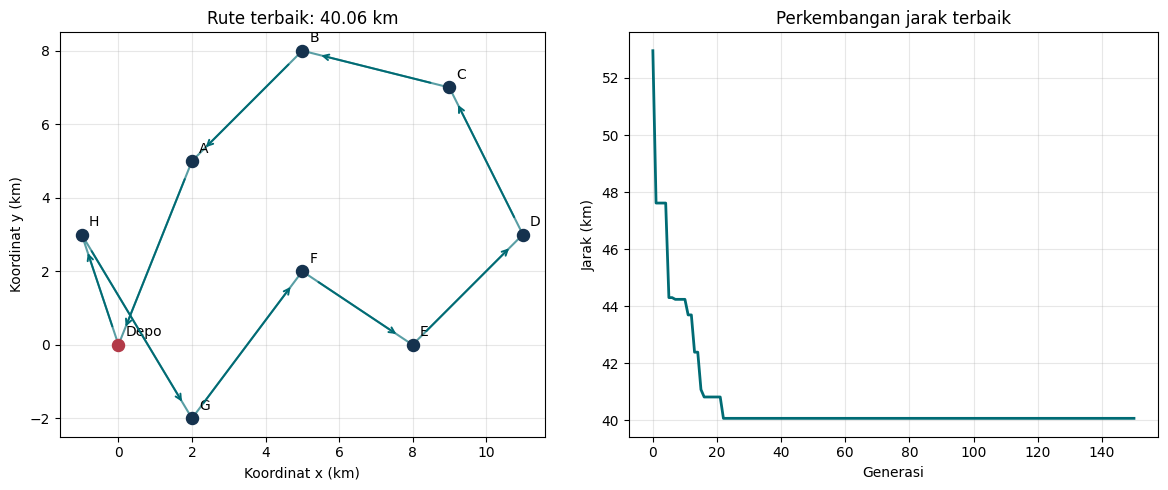

In [8]:
#DONE
if __name__ == "__main__":
    contoh = list(range(1, len(NAMA)))
    assert round(jarak_total(contoh), 2) == 40.06
    assert fitness(contoh) > 0
    
    rng_uji = random.Random(11)
    p1 = [1, 2, 3, 4, 5, 6, 7, 8]
    p2 = [4, 5, 8, 2, 1, 7, 6, 3]
    anak_uji = crossover_urutan(p1, p2, rng_uji)
    assert sorted(anak_uji) == list(range(1, len(NAMA)))
    hasil_mutasi = mutasi_tukar(p1, rng_uji, 1.0)
    assert sorted(hasil_mutasi) == list(range(1, len(NAMA)))
    rute, riwayat = jalankan_ga()
    assert sorted(rute) == list(range(1, len(NAMA)))
    assert math.isclose(jarak_total(rute), riwayat[-1])
    assert all(a >= b for a, b in zip(riwayat, riwayat[1:]))
    lengkap = [0] + rute + [0]
    print("Rute:", " -> ".join(NAMA[i] for i in lengkap))
    print(f"Jarak total: {jarak_total(rute):.2f} km")
    print(f"Jarak terbaik awal/akhir: "
    f"{riwayat[0]:.2f} / {riwayat[-1]:.2f} km")
    gambar_hasil(rute, riwayat)